# Previsão do gasto no fechamento da fatura

**Pergunta:** no meio do ciclo, dá para prever quanto a fatura vai fechar melhor do que a projeção linear que o app já usa ("se continuar gastando no mesmo ritmo"), **com poucas faturas anteriores da pessoa**?

**A ideia:** quem usa o app não tem dezenas de faturas guardadas. Por isso o modelo não aprende com as faturas da pessoa: ele aprende com **muitas pessoas fictícias**, cada uma com o seu jeito de gastar, e na hora de prever olha o ciclo atual da pessoa até a data da previsão e as poucas faturas anteriores que ela tiver.

**Hipóteses:**

1. **H1.** Com o histórico mínimo (seção 5), a Regressão Linear e a Random Forest erram menos que a projeção linear (MAE e RMSE), em pessoas que os modelos nunca viram.
2. **H2.** Sem nenhuma fatura anterior, os modelos não ganham da projeção linear. É daqui que sai o "histórico insuficiente" do app.
3. **H3.** Com o efeito do salário, o ganho dos modelos sobre a projeção linear é maior do que sem ele. (Atenção à leitura, na seção 8: um ganho maior pode vir de a projeção linear piorar com o salário, e não de os modelos aprenderem o salário.)
4. **H4.** Os modelos ganham de uma referência simples, sem aprendizado: "o gasto até agora mais o que a pessoa costuma gastar depois deste mesmo dia do ciclo".
5. **H5.** A faixa provável que o app mostra (intervalo de 80%) contém o valor real em cerca de 80% dos casos, em pessoas novas.

**Dados:** 100% fictícios, criados pelo `ferramentas/gerar_faturas_sinteticas.py --pessoas`. Nenhum dado real entra neste notebook, nem nas saídas.

**Atenção:** o efeito do salário (compras do dia a dia mais prováveis nos dias logo depois do salário) foi **colocado pelo gerador**, de propósito, porque é um padrão comum e a projeção linear não o capta. O notebook mede o resultado com e sem esse efeito (H3). Não há evidência aqui de que pessoas reais tenham esse padrão, nem com essa intensidade.

**Como este notebook foi construído (transparência).** Antes deste notebook houve experimentos exploratórios, fora dele, com duas populações do mesmo gerador (sementes 1 e 2: 80 pessoas de treino e 40 de teste). Eles já mostravam três coisas: os modelos erram muito sem fatura anterior; com histórico, os modelos ficam praticamente empatados com a referência simples da H4; e treinar com um retrato a cada 3 dias não piora o erro. Os atributos dos modelos e as regras de decisão das seções 5 e 6 foram escritos **depois** desses experimentos, então as hipóteses H2 e H4 não são previsões feitas às cegas.

Para a avaliação final ficar limpa, a população de teste usa uma **semente nova (6161)**, que não foi usada em nenhum experimento, teste ou execução anterior. Execuções anteriores deste notebook usaram outras sementes de teste, descartadas:

- **2027.** Usada nas primeiras execuções, antes da revisão.
- **4242.** Revelou que, para quem tem 1 fatura anterior, a faixa provável cobria 92% em vez de cerca de 80%.
  - **Causa:** a calibração dessa faixa vinha de um único ciclo por pessoa (40 no total).
  - **Correção:** a calibração do app passou a simular histórico curto em todos os ciclos (`pv.retratos_com_historico_curto`).
  - **Como a correção foi verificada:** só na população de treino deste notebook (semente 2026), que o modelo do app não viu. Com 1 anterior, a cobertura passou de 84,1% para 77,8%; com 2, de 78,0% para 77,3%.
  - **Depois disso:** o modelo, os atributos e as regras não mudaram mais, e a avaliação final usa a semente nova.
  - **Mudanças de relato depois de ver a semente 6161:**
    - **Referência simples:** o texto do app sobre ela passou de "empatou" para "não foi melhor", e a trava que confere esse texto foi ajustada junto, porque nesta população a Random Forest ficou um pouco pior que ela.
    - **Cobertura:** o número que o app mostra passou a ser o medido aqui.
    - Nada disso altera o modelo. As escolhas (seções 5 a 7) usam só a população de treino; a de teste só aparece nas seções 8 e 9. As únicas constantes do app que vêm da população de teste são números relatados ao usuário (a cobertura da faixa provável), não ajustes do modelo.

In [1]:
import sys
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

PASTA_PROJETO = Path.cwd().parent
sys.path.insert(0, str(PASTA_PROJETO / 'src'))

import fatura as ft
import previsao as pv

SEMENTE_TREINO = 2026
SEMENTE_TESTE = 6161
PESSOAS_TREINO = 80
PESSOAS_TESTE = 40
DOBRAS = 5
REAMOSTRAGENS = 2000
pd.set_option('display.width', 160)

## 1. As pessoas fictícias

Duas populações independentes (sementes diferentes):

- **treino:** 80 pessoas, usadas para escolher e treinar os modelos (com validação cruzada **por pessoa**);
- **teste:** 40 pessoas, usadas só no fim, para a avaliação (seção 8).

Cada pessoa tem 13 faturas seguidas. O perfil é sorteado: quanto gasta, quantas compras faz, o dia de vencimento, as assinaturas e os dias de cobrança, os meses de viagem e de atraso, o tipo de salário (5º dia útil, dia 5, dia 10 ou quinzena) e a intensidade e a duração do efeito do salário.

Cada população existe em dois cenários com **as mesmas pessoas** (mesmo perfil): com o efeito do salário e sem ele (controle).

In [2]:
gerador = pv.carregar_gerador()
populacao_treino = gerador.gerar_populacao(PESSOAS_TREINO, 13, SEMENTE_TREINO, date(2025, 10, 25), True)

linhas = []
for pessoa in populacao_treino:
    perfil = pessoa['perfil']
    linhas.append([
          pessoa['pessoa']
        , round(perfil['escala'], 2)
        , round(perfil['frequencia'], 2)
        , perfil['dia_vencimento']
        , perfil['salario']
        , round(perfil['intensidade'], 2)
        , perfil['duracao']
    ])
df_perfis = pd.DataFrame(linhas, columns=['pessoa', 'escala', 'frequencia', 'dia_vencimento', 'salario', 'intensidade', 'duracao_dias'])
print(df_perfis['salario'].value_counts().to_string())
df_perfis.describe().round(2)

salario
dia 10                    22
dia 5                     21
5º dia útil               19
quinzena (dias 5 e 20)    18


,escala,frequencia,dia_vencimento,intensidade,duracao_dias
count,80.00,80.00,80.00,80.00,80.00
mean,1.28,0.99,18.19,1.70,6.40
std,0.36,0.20,5.05,0.68,1.96
min,0.60,0.71,10.00,0.51,4.00
25%,0.97,0.83,15.00,1.11,5.00
50%,1.37,0.94,20.00,1.68,6.00
75%,1.62,1.19,20.00,2.21,8.00
max,1.77,1.38,25.00,2.98,10.00


**O efeito do salário existe nos dados?** Conferência simples: que fração do gasto do dia a dia (o mesmo conjunto do "ritmo" do app) cai na primeira semana depois de um salário, com e sem o efeito. Sem o efeito, a fração reflete só quantos dias do ciclo estão nessas semanas.

In [3]:
def fracao_depois_do_salario(populacao):
    depois = 0
    total = 0
    for pessoa in populacao:
        for vencimento, linhas in pessoa['faturas']:
            fatura = pv.fatura_das_linhas(gerador, linhas)
            ritmo = fatura[ft.no_ritmo(fatura) & (fatura['centavos'] > 0)]
            for dia, centavos in zip(ritmo['data'].dt.date, ritmo['centavos']):
                total = total + int(centavos)
                if gerador.peso_do_salario(dict(pessoa['perfil'], duracao=7, intensidade=1.0), dia) > 1:
                    depois = depois + int(centavos)
    return depois / total


populacao_treino_sem = gerador.gerar_populacao(PESSOAS_TREINO, 13, SEMENTE_TREINO, date(2025, 10, 25), False)
fracao_com = fracao_depois_do_salario(populacao_treino)
fracao_sem = fracao_depois_do_salario(populacao_treino_sem)
print(f'Gasto do dia a dia na semana depois do salário: com o efeito {fracao_com:.1%}, sem o efeito {fracao_sem:.1%}')
assert fracao_com > fracao_sem

Gasto do dia a dia na semana depois do salário: com o efeito 39.7%, sem o efeito 28.1%


## 2. Retratos: o ciclo visto num dia

Um **retrato** é o ciclo de uma pessoa visto num dia *j* (1 = primeiro dia de compras), com pelo menos um dia de compra pela frente. Cada fatura vira cerca de 30 retratos. O que o modelo vê em cada retrato foi calculado **só com o que se sabia naquele dia**:

| Atributo | O que é |
|---|---|
| `fracao_decorrida` | quanto do ciclo já passou |
| `atual_n` | o gasto até o dia *j* |
| `linear_a_mais_n` | o "a mais" da projeção linear do app |
| `tem_historico`, `anteriores` | se há faturas completas anteriores e quantas |
| `hist_restante_n`, `hist_restante_mediana_n` | quanto a pessoa gastou, em média (e na mediana), **depois do mesmo dia** nas faturas anteriores |
| `hist_fracao_feita` | que fração do total das anteriores já estava gasta no mesmo dia |
| `hist_total_n` | o total médio das anteriores |
| `desvio_n` | o gasto até agora menos o que ela costumava ter gasto até o mesmo dia |

Os valores com `_n` são divididos pela **escala** da pessoa (o total médio das faturas anteriores; sem anteriores, a própria projeção linear), para quem gasta R$ 1.000 e quem gasta R$ 5.000 ficarem comparáveis. O modelo prevê o "a mais" até o fechamento nessa mesma escala; a previsão em reais é o gasto até agora mais esse "a mais" vezes a escala.

Cada fatura passa pelo mesmo caminho de uma fatura de verdade no app (CSV do Nubank, leitura, regras de categoria).

In [4]:
def curvas_das_faturas(populacao):
    resultado = {}
    for pessoa in populacao:
        curvas = []
        for vencimento, linhas in pessoa['faturas']:
            datas = ft.ciclo(vencimento)
            curvas.append(pv.curva(pv.fatura_das_linhas(gerador, linhas), datas['inicio'], datas['ultimo_dia']))
        resultado[pessoa['pessoa']] = curvas
    return resultado


curvas_treino = curvas_das_faturas(populacao_treino)
curvas_treino_sem = curvas_das_faturas(populacao_treino_sem)
curvas_teste = pv.curvas_da_populacao(PESSOAS_TESTE, SEMENTE_TESTE, com_salario=True)
curvas_teste_sem = pv.curvas_da_populacao(PESSOAS_TESTE, SEMENTE_TESTE, com_salario=False)

df_treino = pv.tabela_de_retratos(curvas_treino)
df_treino_sem = pv.tabela_de_retratos(curvas_treino_sem)
df_teste = pv.tabela_de_retratos(curvas_teste)
df_teste_sem = pv.tabela_de_retratos(curvas_teste_sem)
print(len(df_treino), 'retratos de treino e', len(df_teste), 'de teste (com o efeito do salário)')
df_treino[pv.ATRIBUTOS + ['alvo_n']].describe().round(2)

30560 retratos de treino e 15280 de teste (com o efeito do salário)


,fracao_decorrida,atual_n,linear_a_mais_n,tem_historico,anteriores,hist_restante_n,hist_restante_mediana_n,hist_fracao_feita,hist_total_n,desvio_n,alvo_n
count,30560.00,30560.00,30560.00,30560.00,30560.00,30560.00,30560.00,30560.00,30560.00,30560.00,30560.00
mean,0.50,0.57,0.43,0.92,6.01,0.44,0.41,0.53,0.92,0.05,0.54
std,0.28,0.34,0.47,0.26,3.75,0.28,0.28,0.27,0.26,0.23,1.09
min,0.03,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.64,-0.03
25%,0.26,0.31,0.16,1.00,3.00,0.19,0.18,0.31,1.00,-0.09,0.23
50%,0.50,0.54,0.32,1.00,6.00,0.44,0.42,0.52,1.00,0.00,0.45
75%,0.74,0.78,0.56,1.00,9.00,0.67,0.63,0.75,1.00,0.13,0.69
max,0.97,3.19,16.07,1.00,12.00,1.00,1.08,1.00,1.00,2.19,80.06


**Trava 1, só o que se sabia no dia (D2).** Para alguns retratos, o notebook apaga da fatura tudo o que veio **depois** do dia *j* e calcula os atributos de novo. Eles precisam sair idênticos: se algum atributo usasse o futuro, a trava falharia.

**Trava 2, a projeção linear é a do app.** A referência `linear_total` precisa ser igual ao `ft.projecao(...)['projetado']` do app no mesmo dia.

In [5]:
pessoa_exemplo = populacao_treino[0]
vencimento, linhas = pessoa_exemplo['faturas'][5]
datas = ft.ciclo(vencimento)
fatura_exemplo = pv.fatura_das_linhas(gerador, linhas)
anteriores_exemplo = curvas_treino[pessoa_exemplo['pessoa']][:5]
curva_exemplo = pv.curva(fatura_exemplo, datas['inicio'], datas['ultimo_dia'])

conferidos = 0
for j in range(1, curva_exemplo['dias_total']):
    dia = datas['inicio'] + timedelta(days=j - 1)
    completa = pv.atributos(curva_exemplo, j, anteriores_exemplo)
    so_ate_o_dia = fatura_exemplo[fatura_exemplo['data'].dt.date <= dia].reset_index(drop=True)
    truncada = pv.atributos(pv.curva(so_ate_o_dia, datas['inicio'], datas['ultimo_dia']), j, anteriores_exemplo)
    assert completa == truncada, j
    projecao = ft.projecao(fatura_exemplo, datas['inicio'], datas['ultimo_dia'], dia)
    assert completa['atual'] + completa['linear_a_mais'] == projecao['projetado'], j
    conferidos = conferidos + 1
print(conferidos, 'dias conferidos: atributos iguais sem o futuro, e projeção linear igual à do app')

27 dias conferidos: atributos iguais sem o futuro, e projeção linear igual à do app


Como a fatura se acumula ao longo do ciclo, para uma pessoa, nas 13 faturas. Linha tracejada: o dia em que o salário costuma cair. As curvas mudam de inclinação depois dele, o que a projeção linear (uma reta a partir do ritmo até hoje) não acompanha.

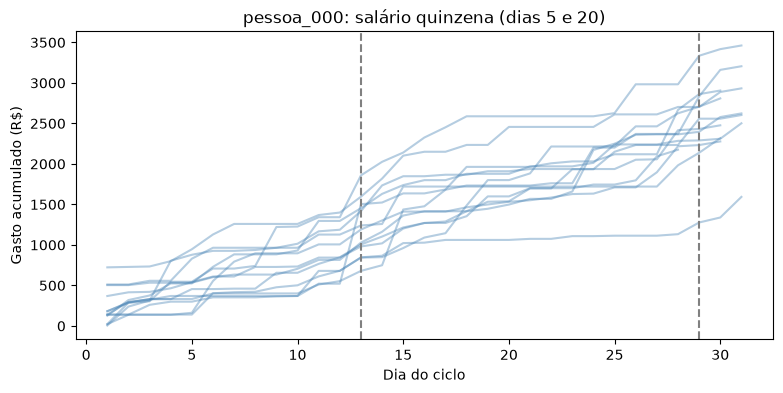

In [6]:
figura, eixo = plt.subplots(figsize=(9, 4))
for curva_pessoa in curvas_treino[pessoa_exemplo['pessoa']]:
    eixo.plot(range(1, curva_pessoa['dias_total'] + 1), curva_pessoa['gasto_ate'] / 100, color='steelblue', alpha=0.4)
inicio_exemplo = curvas_treino[pessoa_exemplo['pessoa']][6]['inicio']
for meses in [0, 1]:
    referencia = ft.somar_meses(date(inicio_exemplo.year, inicio_exemplo.month, 1), meses)
    for pagamento in gerador.dias_de_salario(pessoa_exemplo['perfil']['salario'], referencia.year, referencia.month):
        posicao = (pagamento - inicio_exemplo).days + 1
        if 1 <= posicao <= 31:
            eixo.axvline(posicao, color='gray', linestyle='--')
eixo.set_xlabel('Dia do ciclo')
eixo.set_ylabel('Gasto acumulado (R$)')
eixo.set_title(f'{pessoa_exemplo["pessoa"]}: salário {pessoa_exemplo["perfil"]["salario"]}')
plt.show()

## 3. Como medir

- **Erro:** MAE (erro absoluto médio) e RMSE (raiz do erro quadrático médio), em reais, entre o gasto previsto e o gasto real no fechamento. O RMSE pesa mais os erros grandes.
- **Separação por pessoa:** os retratos do mesmo ciclo e da mesma pessoa são muito parecidos. Por isso a validação cruzada é **agrupada por pessoa** (`GroupKFold`): quem está no teste nunca aparece no treino. Um `KFold` simples misturaria dias do mesmo ciclo em treino e teste e mediria um erro otimista.
- **Só o passado:** cada retrato já usa só as faturas anteriores da pessoa e o ciclo até o dia *j* (trava 1).
- **Incerteza das médias:** intervalo de confiança de 95% por **bootstrap de pessoas** (sorteia pessoas com reposição, 2.000 vezes). Uma diferença é "significativa" quando o intervalo inteiro fica do mesmo lado do zero.
- **Referências:** a projeção linear do app (a comparação pedida) e a referência simples do histórico (H4).

In [7]:
def erros(tabela, previsto):
    return np.abs(tabela['total'].to_numpy() - previsto) / 100


def mae_rmse(tabela, previsto):
    erro = erros(tabela, previsto)
    return erro.mean(), np.sqrt((erro ** 2).mean())


def diferenca_com_intervalo(tabela, previsto_a, previsto_b, semente=0):
    # MAE de A menos MAE de B, com intervalo de 95% por bootstrap de pessoas. Negativo: A erra menos.
    df_erros = pd.DataFrame({
          'pessoa': tabela['pessoa'].to_numpy()
        , 'a': erros(tabela, previsto_a)
        , 'b': erros(tabela, previsto_b)
    })
    por_pessoa = (
        df_erros
        .groupby('pessoa')
        .agg(
              a=('a', 'sum')
            , b=('b', 'sum')
            , n=('a', 'size')
        )
    )
    sorteio = np.random.default_rng(semente)
    diferencas = []
    for _ in range(REAMOSTRAGENS):
        amostra = por_pessoa.iloc[sorteio.integers(0, len(por_pessoa), len(por_pessoa))]
        diferencas.append(amostra['a'].sum() / amostra['n'].sum() - amostra['b'].sum() / amostra['n'].sum())
    centro = df_erros['a'].mean() - df_erros['b'].mean()
    return centro, np.quantile(diferencas, 0.025), np.quantile(diferencas, 0.975)


def historico_simples(tabela):
    # Referência simples (H4): o gasto até agora mais o que a pessoa costuma gastar depois deste dia do ciclo.
    # Sem histórico, não há o que olhar: vale a projeção linear.
    return np.where(tabela['anteriores'] > 0, tabela['atual'] + tabela['hist_restante'], tabela['linear_total'])


def fora_da_dobra(tabela, tipo, folhas=1, passo=1, historico_minimo=0):
    # Previsões de cada retrato por um modelo que não viu aquela pessoa (validação cruzada agrupada por pessoa).
    # O treino pode usar menos retratos (passo e histórico mínimo); a previsão é feita em todos.
    previsto = np.zeros(len(tabela))
    for treino, teste in GroupKFold(n_splits=DOBRAS).split(tabela, groups=tabela['pessoa']):
        parte = pv.retratos_de_treino(tabela.iloc[treino], passo, historico_minimo)
        modelo = pv.treinar(parte, tipo, folhas)
        previsto[teste] = pv.prever_totais(modelo, tabela.iloc[teste])
    return previsto

## 4. Primeira olhada: tudo junto

Os dois modelos, treinados com todos os retratos (com e sem histórico), na validação cruzada por pessoa da população de treino. A Random Forest daqui usa uma configuração provisória (20 folhas e um retrato a cada 3 dias no treino, para caber no tempo); a configuração final é escolhida na seção 6.

In [8]:
oof_linear_regressao = fora_da_dobra(df_treino, pv.REGRESSAO_LINEAR)
oof_floresta = fora_da_dobra(df_treino, pv.FLORESTA, folhas=20, passo=3)

linhas = []
for nome, previsto in [
      ('Projeção linear (app)', df_treino['linear_total'].to_numpy())
    , ('Referência simples do histórico', historico_simples(df_treino))
    , (pv.REGRESSAO_LINEAR, oof_linear_regressao)
    , (pv.FLORESTA, oof_floresta)
]:
    mae, rmse = mae_rmse(df_treino, previsto)
    linhas.append([nome, round(mae), round(rmse)])
pd.DataFrame(linhas, columns=['método', 'MAE (R$)', 'RMSE (R$)'])

,método,MAE (R$),RMSE (R$)
0,Projeção linear (app),791,1351
1,Referência simples do histórico,460,707
2,Regressão Linear,638,1223
3,Random Forest Regressor,502,870


## 5. Histórico mínimo (H2)

O erro de cada método conforme o número de faturas completas anteriores (0, 1, 2, 3 ou mais). Para cada faixa, a diferença de MAE entre o modelo e a projeção linear, com o intervalo de 95%.

**Regra** (escrita depois dos experimentos exploratórios, que já indicavam que sem histórico os modelos perdem): o histórico mínimo é o menor número *k* tal que, em todas as faixas a partir de *k*, **os dois** modelos erram significativamente menos que a projeção linear (intervalo inteiro abaixo de zero). Abaixo dele, o app mostra só a projeção linear e avisa que o histórico ainda é insuficiente.

In [9]:
linhas = []
ganha = {}
for faixa in pv.FAIXAS_HISTORICO:
    filtro = (df_treino['faixa_historico'] == faixa).to_numpy()
    parte = df_treino[filtro]
    ganha[faixa] = True
    for nome, previsto in [(pv.REGRESSAO_LINEAR, oof_linear_regressao[filtro]), (pv.FLORESTA, oof_floresta[filtro])]:
        centro, baixo, alto = diferenca_com_intervalo(parte, previsto, parte['linear_total'].to_numpy())
        linhas.append([
              faixa
            , nome
            , round(mae_rmse(parte, previsto)[0])
            , round(mae_rmse(parte, parte['linear_total'].to_numpy())[0])
            , f'{centro:+.0f} [{baixo:+.0f}; {alto:+.0f}]'
        ])
        if alto >= 0:
            ganha[faixa] = False
df_por_historico = pd.DataFrame(linhas, columns=['faturas anteriores', 'modelo', 'MAE modelo', 'MAE projeção linear', 'diferença (IC 95%)'])
df_por_historico

,faturas anteriores,modelo,MAE modelo,MAE projeção linear,diferença (IC 95%)
0,0,Regressão Linear,2046,670,+1376 [+1127; +1635]
1,0,Random Forest Regressor,870,670,+200 [+123; +280]
2,1,Regressão Linear,547,790,-242 [-338; -136]
3,1,Random Forest Regressor,578,790,-211 [-307; -109]
4,2,Regressão Linear,632,924,-293 [-393; -194]
5,2,Random Forest Regressor,603,924,-321 [-423; -224]
6,3+,Regressão Linear,509,789,-280 [-318; -242]
7,3+,Random Forest Regressor,448,789,-341 [-373; -309]


In [10]:
historico_minimo = None
for posicao, faixa in enumerate(pv.FAIXAS_HISTORICO):
    if all(ganha[outra] for outra in pv.FAIXAS_HISTORICO[posicao:]):
        historico_minimo = posicao
        break
print('Histórico mínimo medido:', historico_minimo, 'fatura(s) completa(s) anterior(es)')
# Trava: o app usa o mesmo mínimo.
assert historico_minimo is not None
assert pv.HISTORICO_MINIMO == historico_minimo, (pv.HISTORICO_MINIMO, historico_minimo)

Histórico mínimo medido: 1 fatura(s) completa(s) anterior(es)


Sem histórico, a escala da pessoa vem da própria projeção linear, que no começo do ciclo se apoia em poucos dias de compra. O modelo herda esse ruído e erra mais. Com uma fatura anterior, a escala e o "o que costuma vir depois deste dia" passam a vir de um ciclo inteiro.

## 6. Configuração do modelo

A partir daqui, só os retratos com o histórico mínimo, porque são os únicos em que o app mostra a previsão por ML. Os modelos também passam a treinar só com eles.

Três escolhas, cada uma com uma regra declarada:

1. **Dias por ciclo no treino.** Treinar com 1 retrato a cada 3 dias deixa o treino de 4 a 5 vezes mais rápido, o que importa porque o app treina ao abrir. A regra: usar 3 se o MAE não piorar significativamente em relação a usar todos os dias.
2. **Folhas da Random Forest** (`min_samples_leaf`, o mínimo de retratos em cada folha: mais folhas, árvores menos detalhistas). A regra: o valor de menor MAE entre 1, 5, 20, 50, 100 e 200. (Numa primeira execução a grade ia até 50 e o melhor caiu na ponta; a grade foi ampliada para que o melhor valor não fique preso no limite.)
3. **Modelo do app.** A regra: a Random Forest só se ela errar significativamente menos que a Regressão Linear; senão, a Regressão Linear, que é mais simples, explicável e treina na hora.

In [11]:
com_historico = (df_treino['anteriores'] >= historico_minimo).to_numpy()
df_avaliado = df_treino[com_historico].reset_index(drop=True)

oof_passo_1 = fora_da_dobra(df_treino, pv.FLORESTA, folhas=20, passo=1, historico_minimo=historico_minimo)[com_historico]
oof_passo_3 = fora_da_dobra(df_treino, pv.FLORESTA, folhas=20, passo=3, historico_minimo=historico_minimo)[com_historico]
centro, baixo, alto = diferenca_com_intervalo(df_avaliado, oof_passo_3, oof_passo_1)
print(f'Random Forest, MAE com 1 retrato a cada 3 dias menos com todos os dias: {centro:+.1f} [{baixo:+.1f}; {alto:+.1f}]')
passo_escolhido = 3
if baixo > 0:
    passo_escolhido = 1
print('Passo escolhido:', passo_escolhido)

Random Forest, MAE com 1 retrato a cada 3 dias menos com todos os dias: -0.0 [-2.1; +2.0]
Passo escolhido: 3


In [12]:
linhas = []
oof_por_folhas = {}
for folhas in [1, 5, 20, 50, 100, 200]:
    previsto = fora_da_dobra(df_treino, pv.FLORESTA, folhas=folhas, passo=passo_escolhido, historico_minimo=historico_minimo)[com_historico]
    oof_por_folhas[folhas] = previsto
    mae, rmse = mae_rmse(df_avaliado, previsto)
    linhas.append([folhas, round(mae, 1), round(rmse, 1)])
df_folhas = pd.DataFrame(linhas, columns=['folhas', 'MAE (R$)', 'RMSE (R$)'])
folhas_escolhidas = int(df_folhas.sort_values('MAE (R$)').iloc[0]['folhas'])
print('Folhas escolhidas:', folhas_escolhidas)
df_folhas

Folhas escolhidas: 50


,folhas,MAE (R$),RMSE (R$)
0,1,465.4,699.6
1,5,453.3,683.3
2,20,443.6,668.5
3,50,442.7,665.9
4,100,444.5,666.6
5,200,448.7,669.8


In [13]:
oof_regressao_final = fora_da_dobra(df_treino, pv.REGRESSAO_LINEAR, passo=passo_escolhido, historico_minimo=historico_minimo)[com_historico]
oof_floresta_final = oof_por_folhas[folhas_escolhidas]
centro, baixo, alto = diferenca_com_intervalo(df_avaliado, oof_floresta_final, oof_regressao_final)
print(f'MAE da Random Forest menos MAE da Regressão Linear: {centro:+.1f} [{baixo:+.1f}; {alto:+.1f}]')
tipo_escolhido = pv.REGRESSAO_LINEAR
if alto < 0:
    tipo_escolhido = pv.FLORESTA
print('Modelo do app:', tipo_escolhido)

# Travas: o app usa a configuração que este notebook escolhe.
assert pv.PASSO_DIAS_APP == passo_escolhido, (pv.PASSO_DIAS_APP, passo_escolhido)
assert pv.TIPO_APP == tipo_escolhido, (pv.TIPO_APP, tipo_escolhido)
if tipo_escolhido == pv.FLORESTA:
    assert pv.FOLHAS_APP == folhas_escolhidas, (pv.FOLHAS_APP, folhas_escolhidas)

MAE da Random Forest menos MAE da Regressão Linear: -6.6 [-10.3; -2.6]
Modelo do app: Random Forest Regressor


## 7. Quantas pessoas fictícias no treino

A curva de aprendizado, só com a população de treino: o modelo escolhido treinado com 10, 20, 40 e 60 das primeiras 60 pessoas e avaliado nas outras 20 pessoas de treino (só os retratos com o histórico mínimo). A população de teste não é usada aqui. A curva é descritiva: mostra se o erro ainda cai com mais pessoas. O app usa 80 pessoas para treinar (o máximo que cabe no tempo de abertura do app, cerca de meio minuto) e outras 40, que o modelo não viu, para medir o erro e a faixa provável (seção 9).

In [14]:
nomes_treino = list(curvas_treino)
validacao = df_treino[df_treino['pessoa'].isin(nomes_treino[60:]) & (df_treino['anteriores'] >= historico_minimo)].reset_index(drop=True)

linhas = []
for quantas in [10, 20, 40, 60]:
    parte = df_treino[df_treino['pessoa'].isin(nomes_treino[:quantas])]
    modelo = pv.treinar(pv.retratos_de_treino(parte, passo_escolhido, historico_minimo), tipo_escolhido, folhas_escolhidas)
    mae, rmse = mae_rmse(validacao, pv.prever_totais(modelo, validacao))
    linhas.append([quantas, round(mae, 1), round(rmse, 1)])
df_aprendizado = pd.DataFrame(linhas, columns=['pessoas no treino', 'MAE na validação (R$)', 'RMSE na validação (R$)'])
assert pv.PESSOAS_TREINO_APP == 80
df_aprendizado

,pessoas no treino,MAE na validação (R$),RMSE na validação (R$)
0,10,443.0,662.9
1,20,444.4,657.2
2,40,439.5,650.8
3,60,436.3,651.8


## 8. Avaliação final nas pessoas de teste (H1, H3, H4)

Os dois modelos, com a configuração escolhida, treinados com as 80 pessoas de treino e avaliados nas 40 pessoas de teste, que não participaram de nenhuma escolha. Nos dois cenários: com e sem o efeito do salário (cada cenário treina e testa no seu).

In [15]:
teste_com_historico = (df_teste['anteriores'] >= historico_minimo).to_numpy()
df_teste_avaliado = df_teste[teste_com_historico].reset_index(drop=True)


def avaliar_cenario(treino, teste):
    filtro = (teste['anteriores'] >= historico_minimo).to_numpy()
    avaliado = teste[filtro].reset_index(drop=True)
    treino_usado = pv.retratos_de_treino(treino, passo_escolhido, historico_minimo)
    previstos = {
          'Projeção linear (app)': avaliado['linear_total'].to_numpy()
        , 'Referência simples do histórico': historico_simples(avaliado)
        , pv.REGRESSAO_LINEAR: pv.prever_totais(pv.treinar(treino_usado, pv.REGRESSAO_LINEAR), avaliado)
        , pv.FLORESTA: pv.prever_totais(pv.treinar(treino_usado, pv.FLORESTA, folhas_escolhidas), avaliado)
    }
    return avaliado, previstos


avaliado_com, previstos_com = avaliar_cenario(df_treino, df_teste)
avaliado_sem, previstos_sem = avaliar_cenario(df_treino_sem, df_teste_sem)

linhas = []
for cenario, avaliado, previstos in [('com salário', avaliado_com, previstos_com), ('sem salário', avaliado_sem, previstos_sem)]:
    for nome, previsto in previstos.items():
        mae, rmse = mae_rmse(avaliado, previsto)
        linhas.append([cenario, nome, round(mae), round(rmse)])
df_final = pd.DataFrame(linhas, columns=['cenário', 'método', 'MAE (R$)', 'RMSE (R$)'])
df_final

,cenário,método,MAE (R$),RMSE (R$)
0,com salário,Projeção linear (app),774,1319
1,com salário,Referência simples do histórico,394,589
2,com salário,Regressão Linear,409,600
3,com salário,Random Forest Regressor,405,595
4,sem salário,Projeção linear (app),688,1149
5,sem salário,Referência simples do histórico,392,589
6,sem salário,Regressão Linear,397,589
7,sem salário,Random Forest Regressor,391,581


In [16]:
linhas = []
for cenario, avaliado, previstos in [('com salário', avaliado_com, previstos_com), ('sem salário', avaliado_sem, previstos_sem)]:
    for nome in [pv.REGRESSAO_LINEAR, pv.FLORESTA]:
        for referencia in ['Projeção linear (app)', 'Referência simples do histórico']:
            centro, baixo, alto = diferenca_com_intervalo(avaliado, previstos[nome], previstos[referencia])
            linhas.append([cenario, nome, referencia, int(round(centro)), int(round(baixo)), int(round(alto))])
df_diferencas = pd.DataFrame(linhas, columns=['cenário', 'modelo', 'comparado com', 'diferença de MAE', 'IC 2,5%', 'IC 97,5%'])
df_diferencas

,cenário,modelo,comparado com,diferença de MAE,"IC 2,5%","IC 97,5%"
0,com salário,Regressão Linear,Projeção linear (app),-366,-419,-317
1,com salário,Regressão Linear,Referência simples do histórico,15,4,26
2,com salário,Random Forest Regressor,Projeção linear (app),-370,-423,-320
3,com salário,Random Forest Regressor,Referência simples do histórico,11,1,21
4,sem salário,Regressão Linear,Projeção linear (app),-291,-326,-256
5,sem salário,Regressão Linear,Referência simples do histórico,4,-4,12
6,sem salário,Random Forest Regressor,Projeção linear (app),-297,-333,-262
7,sem salário,Random Forest Regressor,Referência simples do histórico,-1,-7,4


**Com poucas faturas.** O objetivo do app é funcionar com poucas faturas. Os números acima misturam pessoas com 1 a 12 faturas anteriores; abaixo, separados por quantas faturas anteriores a pessoa tinha, no cenário com salário, com a diferença da Random Forest para a projeção linear (centro e intervalo de 95%). Trava: com o histórico mínimo, a Random Forest precisa errar significativamente menos que a projeção linear.

In [17]:
linhas = []
ganha_por_historico_teste = {}
for faixa in ['1', '2', '3+']:
    filtro = (avaliado_com['faixa_historico'] == faixa).to_numpy()
    parte = avaliado_com[filtro].reset_index(drop=True)
    for nome, previsto in previstos_com.items():
        mae, rmse = mae_rmse(parte, previsto[filtro])
        linhas.append([faixa, nome, round(mae), round(rmse)])
    ganha_por_historico_teste[faixa] = diferenca_com_intervalo(parte, previstos_com[pv.FLORESTA][filtro], parte['linear_total'].to_numpy())
df_teste_por_historico = pd.DataFrame(linhas, columns=['faturas anteriores', 'método', 'MAE (R$)', 'RMSE (R$)'])
print({faixa: tuple(round(v) for v in valores) for faixa, valores in ganha_por_historico_teste.items()})
faixa_minima = pv.faixa_do_historico(pv.HISTORICO_MINIMO)
assert ganha_por_historico_teste[faixa_minima][2] < 0, ganha_por_historico_teste[faixa_minima]
df_teste_por_historico

{'1': (-168, -303, -13), '2': (-386, -527, -261), '3+': (-389, -440, -339)}


,faturas anteriores,método,MAE (R$),RMSE (R$)
0,1,Projeção linear (app),679,1090
1,1,Referência simples do histórico,525,794
2,1,Regressão Linear,526,815
3,1,Random Forest Regressor,511,796
4,2,Projeção linear (app),798,1309
5,2,Referência simples do histórico,420,647
6,2,Regressão Linear,422,631
7,2,Random Forest Regressor,412,617
8,3+,Projeção linear (app),782,1342
9,3+,Referência simples do histórico,378,558


In [18]:
# Trava: o texto do app diz que o modelo "não foi melhor" que a referência simples. Se a Random Forest passar a
# errar significativamente menos que ela, o texto do app precisa mudar.
linha_empate = df_diferencas[
      (df_diferencas['cenário'] == 'com salário')
    & (df_diferencas['modelo'] == pv.FLORESTA)
    & (df_diferencas['comparado com'] == 'Referência simples do histórico')
].iloc[0]
print('Random Forest menos referência simples:', linha_empate['diferença de MAE'], [linha_empate['IC 2,5%'], linha_empate['IC 97,5%']])
assert not linha_empate['IC 97,5%'] < 0, 'o texto do app diz "não foi melhor"'

Random Forest menos referência simples: 11 [np.int64(1), np.int64(21)]


O erro por faixa do ciclo, no cenário com salário. No começo do ciclo há mais coisa por acontecer, e todos os métodos erram mais.

In [19]:
linhas = []
for faixa in pv.FAIXAS_CICLO:
    filtro = (avaliado_com['faixa_ciclo'] == faixa).to_numpy()
    for nome, previsto in previstos_com.items():
        mae, rmse = mae_rmse(avaliado_com[filtro], previsto[filtro])
        linhas.append([faixa, nome, round(mae), round(rmse)])
df_por_faixa = pd.DataFrame(linhas, columns=['faixa do ciclo', 'método', 'MAE (R$)', 'RMSE (R$)'])
df_por_faixa.pivot(index='método', columns='faixa do ciclo', values='MAE (R$)')[pv.FAIXAS_CICLO]

faixa do ciclo,início do ciclo,meio do ciclo,fim do ciclo
método,,,
Projeção linear (app),1438,603,265
Random Forest Regressor,548,427,232
Referência simples do histórico,533,414,228
Regressão Linear,564,425,231


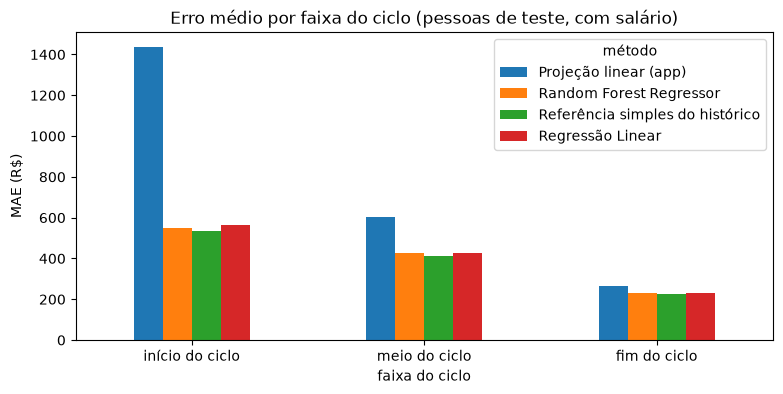

In [20]:
tabela_grafico = df_por_faixa.pivot(index='faixa do ciclo', columns='método', values='MAE (R$)').loc[pv.FAIXAS_CICLO]
eixo = tabela_grafico.plot(kind='bar', figsize=(9, 4), rot=0)
eixo.set_ylabel('MAE (R$)')
eixo.set_title('Erro médio por faixa do ciclo (pessoas de teste, com salário)')
plt.show()

**H3, o ganho vem do salário?** O ganho de cada modelo sobre a projeção linear (MAE da projeção menos MAE do modelo), com e sem o efeito do salário, para as mesmas 40 pessoas de teste. A diferença entre os dois ganhos tem intervalo por bootstrap de pessoas.

In [21]:
def ganho_com_menos_sem(nome, semente=0):
    tabela_com = pd.DataFrame({
          'pessoa': avaliado_com['pessoa'].to_numpy()
        , 'ganho': erros(avaliado_com, previstos_com['Projeção linear (app)']) - erros(avaliado_com, previstos_com[nome])
    })
    tabela_sem = pd.DataFrame({
          'pessoa': avaliado_sem['pessoa'].to_numpy()
        , 'ganho': erros(avaliado_sem, previstos_sem['Projeção linear (app)']) - erros(avaliado_sem, previstos_sem[nome])
    })
    soma_com = tabela_com.groupby('pessoa')['ganho'].agg(['sum', 'size'])
    soma_sem = tabela_sem.groupby('pessoa')['ganho'].agg(['sum', 'size'])
    pessoas = list(soma_com.index)
    sorteio = np.random.default_rng(semente)
    diferencas = []
    for _ in range(REAMOSTRAGENS):
        escolhidas = [pessoas[posicao] for posicao in sorteio.integers(0, len(pessoas), len(pessoas))]
        com = soma_com.loc[escolhidas]
        sem = soma_sem.loc[escolhidas]
        diferencas.append(com['sum'].sum() / com['size'].sum() - sem['sum'].sum() / sem['size'].sum())
    centro = tabela_com['ganho'].mean() - tabela_sem['ganho'].mean()
    return tabela_com['ganho'].mean(), tabela_sem['ganho'].mean(), centro, np.quantile(diferencas, 0.025), np.quantile(diferencas, 0.975)


linhas = []
for nome in [pv.REGRESSAO_LINEAR, pv.FLORESTA]:
    ganho_com, ganho_sem, centro, baixo, alto = ganho_com_menos_sem(nome)
    linhas.append([nome, round(ganho_com), round(ganho_sem), f'{centro:+.0f} [{baixo:+.0f}; {alto:+.0f}]'])
df_ganho_salario = pd.DataFrame(linhas, columns=['modelo', 'ganho com salário (R$)', 'ganho sem salário (R$)', 'com menos sem (IC 95%)'])
df_ganho_salario

,modelo,ganho com salário (R$),ganho sem salário (R$),com menos sem (IC 95%)
0,Regressão Linear,366,291,+75 [+47; +106]
1,Random Forest Regressor,370,297,+73 [+45; +103]


**Como ler a H3.** O ganho é a diferença entre dois erros, então ele cresce se o modelo melhorar **ou** se a projeção linear piorar. A célula abaixo separa as duas coisas: o MAE de cada método com e sem o efeito do salário. Se o erro dos modelos (e da referência simples, que não aprende nada) quase não muda e o da projeção linear sobe, o ganho maior vem da projeção linear errar mais com o salário, não de os modelos "aprenderem o salário". Usar o histórico da pessoa no mesmo ponto do ciclo já capta o efeito.

In [22]:
linhas = []
for nome in previstos_com:
    mae_com = mae_rmse(avaliado_com, previstos_com[nome])[0]
    mae_sem = mae_rmse(avaliado_sem, previstos_sem[nome])[0]
    linhas.append([nome, round(mae_com), round(mae_sem), round(mae_com - mae_sem)])
pd.DataFrame(linhas, columns=['método', 'MAE com salário (R$)', 'MAE sem salário (R$)', 'com menos sem (R$)'])

,método,MAE com salário (R$),MAE sem salário (R$),com menos sem (R$)
0,Projeção linear (app),774,688,86
1,Referência simples do histórico,394,392,1
2,Regressão Linear,409,397,12
3,Random Forest Regressor,405,391,14


## 9. A faixa provável do app (H5)

O app treina o modelo com outra população (semente própria, 80 pessoas) e mede os erros em mais 40 pessoas que o modelo não viu. Nessas 40, além dos ciclos como eles são, cada ciclo também é visto como se a pessoa só tivesse 1 ou 2 faturas anteriores (histórico cortado), para as faixas de quem tem pouco histórico não dependerem de um ciclo por pessoa. Os quantis de 10% e 90% desses erros, por faixa do ciclo e de histórico, viram a **faixa provável**; o erro absoluto médio vira o **erro típico** mostrado ao usuário.

Aqui o notebook treina exatamente o modelo do app (`pv.treinar_para_app()`) e confere, nas 40 pessoas de teste deste notebook, em quantos casos o gasto real ficou dentro da faixa. O esperado é perto de 80%.

Antes, quantos retratos de teste ficam **fora do que o modelo viu no treino** (algum atributo fora da faixa do treino). Nesses casos o app não mostra o número do modelo, só a projeção linear; a cobertura é medida nos demais, que são os que o app mostra.

In [23]:
treinado_app = pv.treinar_para_app()
assert treinado_app['tipo'] == tipo_escolhido

fora = []
for linha in df_teste_avaliado[pv.ATRIBUTOS].to_dict('records'):
    fora.append(len(pv.fora_do_treino(treinado_app['limites'], linha)) > 0)
fora = np.array(fora)
print(f'Retratos de teste fora do treino: {fora.mean():.2%} ({fora.sum()} de {len(fora)})')
contagem_por_atributo = {}
for linha in df_teste_avaliado[pv.ATRIBUTOS].to_dict('records'):
    for atributo in pv.fora_do_treino(treinado_app['limites'], linha):
        contagem_por_atributo[atributo] = contagem_por_atributo.get(atributo, 0) + 1
print('Atributos fora da faixa do treino (retratos):', contagem_por_atributo)
df_mostrados = df_teste_avaliado[~fora].reset_index(drop=True)

previstos_app = pv.prever_totais(treinado_app['modelo'], df_mostrados)
dentro = []
for posicao, linha in enumerate(df_mostrados.itertuples(index=False)):
    medido = treinado_app['quantis'][(linha.faixa_ciclo, linha.faixa_historico)]
    baixo = max(previstos_app[posicao] + medido['baixo'] * linha.escala, linha.atual)
    alto = max(previstos_app[posicao] + medido['alto'] * linha.escala, baixo)
    dentro.append(baixo <= linha.total <= alto)
df_cobertura = pd.DataFrame({
      'pessoa': df_mostrados['pessoa']
    , 'faixa_ciclo': df_mostrados['faixa_ciclo']
    , 'dentro': dentro
})

por_pessoa = df_cobertura.groupby('pessoa')['dentro'].agg(['sum', 'size'])
sorteio = np.random.default_rng(0)
coberturas = []
for _ in range(REAMOSTRAGENS):
    amostra = por_pessoa.iloc[sorteio.integers(0, len(por_pessoa), len(por_pessoa))]
    coberturas.append(amostra['sum'].sum() / amostra['size'].sum())
cobertura = df_cobertura['dentro'].mean()
cobertura_baixo = np.quantile(coberturas, 0.025)
cobertura_alto = np.quantile(coberturas, 0.975)
print(f'Cobertura da faixa provável: {cobertura:.1%} [{cobertura_baixo:.1%}; {cobertura_alto:.1%}] (esperado: 80%)')
print(df_cobertura.groupby('faixa_ciclo')['dentro'].mean().loc[pv.FAIXAS_CICLO].round(3).to_string())
mae_app, rmse_app = mae_rmse(df_mostrados, previstos_app)
mae_linear_mostrados, rmse_linear_mostrados = mae_rmse(df_mostrados, df_mostrados['linear_total'].to_numpy())
print(f'Modelo do app nas pessoas de teste: MAE R$ {mae_app:.0f}, RMSE R$ {rmse_app:.0f} (projeção linear nos mesmos retratos: MAE R$ {mae_linear_mostrados:.0f}, RMSE R$ {rmse_linear_mostrados:.0f})')

# Trava: o texto do app sobre a faixa provável usa a cobertura medida aqui.
assert pv.COBERTURA_MEDIDA == round(cobertura, 2), (pv.COBERTURA_MEDIDA, round(cobertura, 2))

Retratos de teste fora do treino: 0.00% (0 de 14120)
Atributos fora da faixa do treino (retratos): {}


Cobertura da faixa provável: 79.0% [76.4%; 81.4%] (esperado: 80%)
faixa_ciclo
início do ciclo    0.812
meio do ciclo      0.784
fim do ciclo       0.772
Modelo do app nas pessoas de teste: MAE R$ 395, RMSE R$ 585 (projeção linear nos mesmos retratos: MAE R$ 774, RMSE R$ 1319)


A cobertura por faixa de histórico e por faixa do ciclo, com intervalo de 95% por bootstrap de pessoas. Trava: o app diz o mesmo número para qualquer situação, então ele precisa caber no intervalo de cada faixa.

In [24]:
df_cobertura['faixa_historico'] = df_mostrados['faixa_historico'].to_numpy()
for coluna, faixas in [('faixa_historico', ['1', '2', '3+']), ('faixa_ciclo', pv.FAIXAS_CICLO)]:
    for faixa in faixas:
        parte = df_cobertura[df_cobertura[coluna] == faixa]
        por_pessoa_faixa = parte.groupby('pessoa')['dentro'].agg(['sum', 'size'])
        sorteio_faixa = np.random.default_rng(0)
        amostras = []
        for _ in range(REAMOSTRAGENS):
            amostra = por_pessoa_faixa.iloc[sorteio_faixa.integers(0, len(por_pessoa_faixa), len(por_pessoa_faixa))]
            amostras.append(amostra['sum'].sum() / amostra['size'].sum())
        baixo, alto = np.quantile(amostras, 0.025), np.quantile(amostras, 0.975)
        print(f'Cobertura ({coluna} = {faixa}): {parte["dentro"].mean():.1%} [{baixo:.1%}; {alto:.1%}]')
        # Trava: o app diz "80% das vezes" em qualquer faixa.
        assert baixo <= pv.COBERTURA_MEDIDA <= alto, (coluna, faixa, baixo, alto)

Cobertura (faixa_historico = 1): 80.2% [72.6%; 86.8%]


Cobertura (faixa_historico = 2): 79.6% [72.8%; 86.2%]


Cobertura (faixa_historico = 3+): 78.8% [76.0%; 81.6%]


Cobertura (faixa_ciclo = início do ciclo): 81.2% [77.9%; 84.5%]


Cobertura (faixa_ciclo = meio do ciclo): 78.4% [75.3%; 81.5%]


Cobertura (faixa_ciclo = fim do ciclo): 77.2% [74.2%; 80.1%]


In [25]:
linhas = []
for (faixa_ciclo, faixa_historico), medido in treinado_app['quantis'].items():
    linhas.append([
          faixa_ciclo
        , faixa_historico
        , medido['ciclos']
        , round(medido['baixo'], 3)
        , round(medido['alto'], 3)
        , round(medido['erro_medio'], 3)
        , round(medido['erro_medio_linear'], 3)
    ])
pd.DataFrame(linhas, columns=['faixa do ciclo', 'faturas anteriores', 'ciclos medidos', 'quantil 10%', 'quantil 90%', 'erro médio (modelo)', 'erro médio (projeção linear)'])

,faixa do ciclo,faturas anteriores,ciclos medidos,quantil 10%,quantil 90%,erro médio (modelo),erro médio (projeção linear)
0,início do ciclo,0,40,-0.172,4.230,2.507,2.480
1,início do ciclo,1,480,-0.279,0.437,0.212,0.482
2,início do ciclo,2,440,-0.269,0.322,0.188,0.463
3,início do ciclo,3+,400,-0.233,0.321,0.175,0.461
4,meio do ciclo,0,40,-0.149,0.631,0.267,0.246
5,meio do ciclo,1,480,-0.217,0.293,0.159,0.200
6,meio do ciclo,2,440,-0.207,0.242,0.143,0.195
7,meio do ciclo,3+,400,-0.173,0.233,0.132,0.198
8,fim do ciclo,0,40,-0.087,0.195,0.089,0.087
9,fim do ciclo,1,480,-0.147,0.127,0.089,0.085


Os valores da tabela acima estão na escala da pessoa (1,0 = o total médio das faturas anteriores dela). No app, eles são multiplicados pela escala de quem está usando.

## 10. Veredito das hipóteses

In [26]:
def veredito(confirmada, detalhe):
    if confirmada:
        return 'CONFIRMADA: ' + detalhe
    return 'NÃO CONFIRMADA: ' + detalhe


def linha_diferenca(cenario, nome, referencia):
    filtro = (
          (df_diferencas['cenário'] == cenario)
        & (df_diferencas['modelo'] == nome)
        & (df_diferencas['comparado com'] == referencia)
    )
    return df_diferencas[filtro].iloc[0]


h1 = True
detalhes_h1 = []
for nome in [pv.REGRESSAO_LINEAR, pv.FLORESTA]:
    linha = linha_diferenca('com salário', nome, 'Projeção linear (app)')
    h1 = h1 and linha['IC 97,5%'] < 0
    detalhes_h1.append(f'{nome} {linha["diferença de MAE"]:+d} [{linha["IC 2,5%"]:+d}; {linha["IC 97,5%"]:+d}]')

h2 = not ganha['0']

h3 = True
detalhes_h3 = []
for linha in df_ganho_salario.itertuples(index=False):
    centro, ganho_com_baixo, ganho_com_alto = ganho_com_menos_sem(linha.modelo)[2:]
    h3 = h3 and ganho_com_baixo > 0
    detalhes_h3.append(f'{linha.modelo}: {linha[3]}')

h4 = True
detalhes_h4 = []
for nome in [pv.REGRESSAO_LINEAR, pv.FLORESTA]:
    linha = linha_diferenca('com salário', nome, 'Referência simples do histórico')
    h4 = h4 and linha['IC 97,5%'] < 0
    detalhes_h4.append(f'{nome} {linha["diferença de MAE"]:+d} [{linha["IC 2,5%"]:+d}; {linha["IC 97,5%"]:+d}]')

h5 = cobertura_baixo <= 0.80 <= cobertura_alto

print('H1 (modelos x projeção linear, com histórico):', veredito(h1, '; '.join(detalhes_h1)))
print('H2 (sem histórico os modelos não ganham):', veredito(h2, f'histórico mínimo medido = {historico_minimo}'))
print('H3 (ganho maior com o efeito do salário):', veredito(h3, '; '.join(detalhes_h3)))
print('H4 (modelos x referência simples do histórico):', veredito(h4, '; '.join(detalhes_h4)))
print('H5 (faixa provável cobre ~80%):', veredito(h5, f'{cobertura:.1%} [{cobertura_baixo:.1%}; {cobertura_alto:.1%}]'))

H1 (modelos x projeção linear, com histórico): CONFIRMADA: Regressão Linear -366 [-419; -317]; Random Forest Regressor -370 [-423; -320]
H2 (sem histórico os modelos não ganham): CONFIRMADA: histórico mínimo medido = 1
H3 (ganho maior com o efeito do salário): CONFIRMADA: Regressão Linear: +75 [+47; +106]; Random Forest Regressor: +73 [+45; +103]
H4 (modelos x referência simples do histórico): NÃO CONFIRMADA: Regressão Linear +15 [+4; +26]; Random Forest Regressor +11 [+1; +21]
H5 (faixa provável cobre ~80%): CONFIRMADA: 79.0% [76.4%; 81.4%]


## 11. Conclusão e limitações

**O que foi para o app.** O modelo escolhido na seção 6, treinado com 80 pessoas fictícias e com o erro medido em outras 40. Ele só aparece a partir do histórico mínimo da seção 5. Abaixo disso, o app avisa que o histórico ainda é insuficiente e mostra só a projeção linear, com o erro típico dela. As travas deste notebook falham se a configuração do app ficar diferente do que foi medido aqui.

**Como ler os resultados.** Os vereditos acima são calculados, não escritos à mão. Em especial, a H4 compara os modelos com uma referência simples que não aprende nada. Se ela não for confirmada, o ganho sobre a projeção linear vem principalmente de **usar o histórico da pessoa no mesmo ponto do ciclo**, e os modelos aprendem a fazer isso, sem ir além (na população de teste desta execução, a Random Forest ficou até um pouco pior que a referência simples; numa população anterior, empatou). Isso é um resultado, não um defeito escondido: o modelo do app continua sendo aprendizado de máquina, e a referência simples mostra o tamanho real do ganho.

**Limitações:**

- **Pessoas fictícias.** Todas as pessoas, de treino e de teste, vêm do mesmo gerador. O modelo aprende o jeito do gerador, e o erro medido vale para pessoas parecidas com essas. Pessoas reais podem ter outros padrões, e o erro real pode ser maior.
- **Padrão colocado por construção.** O efeito do salário foi posto de propósito (seção 1). A seção 8 mostra que ele piora a projeção linear; os modelos e a referência simples, que usam o histórico da pessoa, quase não mudam com ele.
- **Escolhas feitas depois de experimentos exploratórios.** Os atributos e as regras das seções 5 e 6 foram escritos depois de experimentos fora deste notebook (ver a introdução). A avaliação final usa uma semente de teste nova para não ser afetada por isso.
- **Poucos ciclos com 1 ou 2 faturas anteriores.** Cada pessoa de teste tem só um ciclo com 1 anterior e um com 2; os números dessas faixas vêm de 40 ciclos cada e têm intervalos largos.
- **A fatura real não entra na avaliação.** Existe uma única fatura real e ela não aparece neste notebook, por privacidade e porque um ciclo só não mede erro.
- **Histórico curto no treino.** Cada pessoa tem 13 faturas, então no treino há no máximo 12 anteriores. O app usa as 12 mais recentes.
- **Faixa provável.** Ela é medida em pessoas fictícias. Se o comportamento real for mais irregular, a faixa será estreita demais. No app, o limite de baixo nunca fica abaixo do gasto até agora; só um estorno faria a fatura fechar abaixo disso.
- **Só o total.** O modelo prevê o gasto total do período, não por categoria. As metas por categoria continuam com a projeção linear.